<a href="https://colab.research.google.com/github/tylerdunc101/Earthquake-Project/blob/main/Earthquake_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import r2_score
from sklearn.metrics import RocCurveDisplay

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
eq = pd.read_csv("/content/drive/MyDrive/Earthquake_Project/earthquakes.tsv", sep="\t")
eq.shape

(6698, 39)

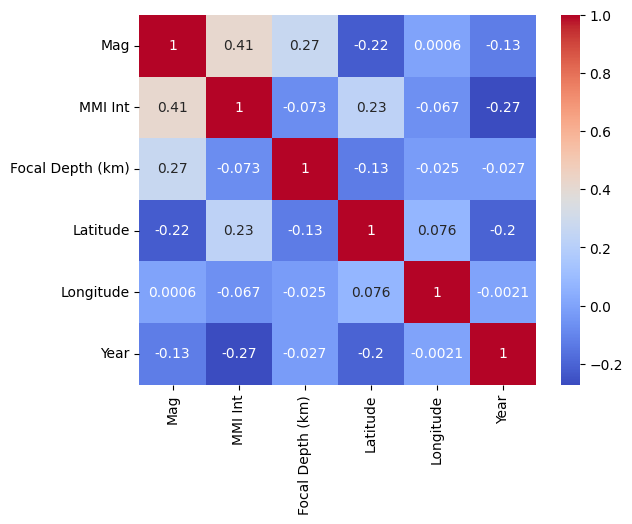

In [ ]:
#correlation matrix
features = ["Mag","MMI Int","Focal Depth (km)","Latitude","Longitude","Year"]
corr_matrix = eq[features].corr()
sns.heatmap(corr_matrix, annot=True,cmap ="coolwarm")
plt.show()

This matrix showcases how this dataset is not the best for regression as the variables have little linear correlation. As a result, standard linear models are largly uninteresting or not useful at all. This weak linear relationship is a well-known characteristic of geophysical and geospatial datasets, which are inherently non-linear. While standard linear models fall short other models that do not rely on features being linearly correlated such as decision trees can prove useful to us.

This model is poor for regression as only mag and mmi int have a useful comparison

In [ ]:
cols = ["Mag","MMI Int"]
lineareq = eq.dropna(subset=cols)
eq.shape

(6698, 39)

In [ ]:
#linear regression using mag and Deaths
X= lineareq["Mag"].values.reshape(-1,1)
y=lineareq["MMI Int"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)
print(linear_model.coef_)
print(linear_model.intercept_)
print(r2_score(y_test, y_pred))

[0.75296574]
2.8956118031960285
0.18741777480605526


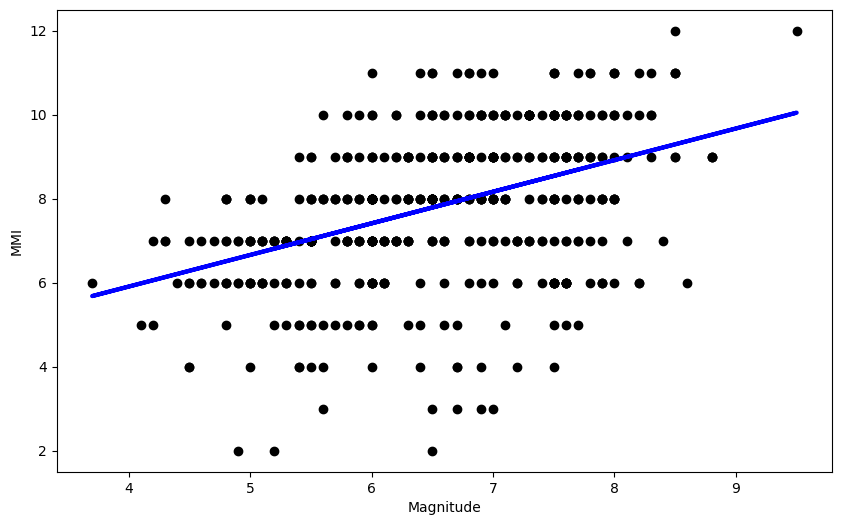

In [ ]:
# map out linear regression model
plt.figure(figsize=(10,6))
plt.scatter(X_test, y_test, color='black')
plt.xlabel('Magnitude')
plt.ylabel('MMI')
plt.plot(X_test, y_pred, color='blue', linewidth=3)

These two features used on the simple linear regression model are the really only two features we can extract useful information from. Although it may not be interesting those two are the only two that are linearly correlated.

**Multi-linear Regression**

In [ ]:
mult_eq = eq.dropna(subset=["Mag", "MMI Int", "Focal Depth (km)", "Latitude", "Longitude"])
mult_eq.shape

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

X = mult_eq[["Mag", "Focal Depth (km)", "Latitude", "Longitude"]].copy()
y = mult_eq["MMI Int"]

X["Focal Depth (km)"] = np.log1p(X["Focal Depth (km)"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

multmodel = LinearRegression()
multmodel.fit(X_train, y_train)

print(multmodel.coef_)
print(multmodel.intercept_)

y_pred = multmodel.predict(X_test)

print("R-squared:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))


[ 0.85321748 -0.20336186  0.4537192  -0.17428673]
7.41611234294161
R-squared: 0.19825306262814668
MSE: 2.583302150622376


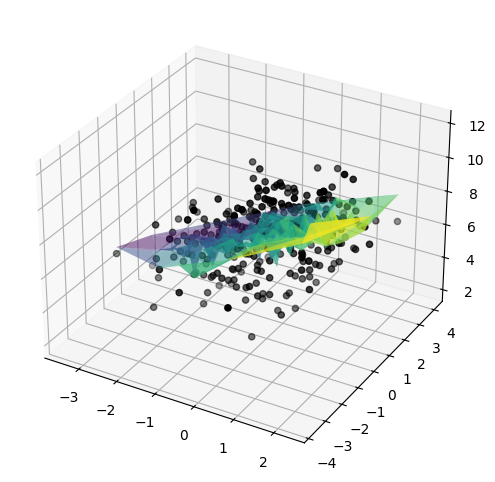

In [ ]:
#map out multi linear regression
fig = plt.figure(figsize=(10,6))
#map prediction line
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_test[:,0], X_test[:,1], y_test, color='black')
ax.plot_trisurf(
    X_test[:, 0],
    X_test[:, 1],
    y_pred,
    cmap="viridis",
    alpha=0.5)

This model was the best we came together with and it has obvious issues specifically with r-squared and mse. The r-squared shows us that the model is only accounting for 20 percent of patterns in the earthquakes. For the MSE, because MMI Int is only on a 1-10 scale that means the models predicition is roughly 1.6 off. With the model being up to 1.6 off that can prove troublesome in the real world as differences in the mmi scale could cause damage to life and property.

**Logistic Regression**

In [ ]:
eq = eq.fillna({"Tsu": 0})
eq["Tsu"] = eq["Tsu"].apply(lambda x: 1 if x != 0 else 0)

eq = eq.dropna(subset=["Mag", "Focal Depth (km)", "Latitude", "Longitude"])

X = eq[["Mag", "Focal Depth (km)", "Latitude", "Longitude"]]
y = eq["Tsu"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_train, y_train)

print(clf.coef_)
print(clf.intercept_)

y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

[[ 1.27389018 -0.00719505 -0.00690589  0.00157671]]
[-8.1153904]
Accuracy: 0.7338935574229691
Precision: 0.5204081632653061
Recall: 0.7574257425742574
F1 Score: 0.6169354838709677


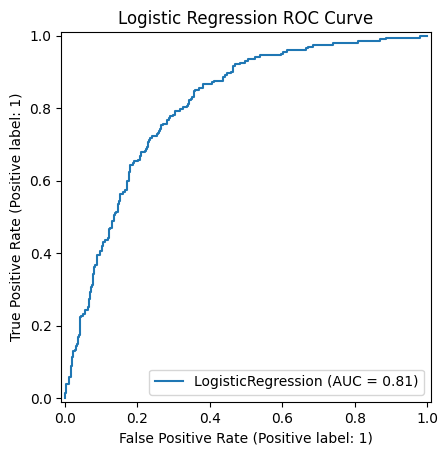

In [ ]:
RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.title("Logistic Regression ROC Curve")
plt.show()

An AUC score of 0.81 means that our logistic regression model did a pretty good job distinguishing between earthquakes that caused tsunamis, and ones that didn't. Overall, the model shows strong proof that these chosen earthquake factors are useful when predicting weather or not an earthquake caused a tsunami.